<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_25_Category_Selectivity_Via_Cosine_Similarity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

from scipy.stats import ttest_ind
import requests

from transformers import AutoModelForCausalLM, AutoTokenizer


# Part_1:Model,Token,hidden_states

## Task_1:
- Import GPT-2-small and its tokenizer. When importing the model,
toggle the optional input argument output_hidden_states to be
True. Switch the model to evaluation mode.
The online code file has a variable words that contains 34 words in
three semantic categories (space, furniture, fruit). Confirm that the
words are each encoded using only one token when they include a
preceding space.

In [2]:
model=AutoModelForCausalLM.from_pretrained('gpt2',output_hidden_states=True)
tokenizer=AutoTokenizer.from_pretrained('gpt2')
model.eval()

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] The following generation flags are not valid and may be ignored: ['output_hidden_states']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [11]:
words = [
    [1, 'galaxy'],
    [1, 'asteroid'],
    [1, 'comet'],
    [1, 'cosmos'],
    [1, 'space'],
    [1, 'sun'],
    [1, 'planet'],
    [1, 'moon'],
    [1, 'star'],
    [1, 'orbit'],
    [2, 'ceiling'],
    [2, 'sofa'],
    [2, 'couch'],
    [2, 'carpet'],
    [2, 'door'],
    [2, 'window'],
    [2, 'lamp'],
    [2, 'chair'],
    [2, 'table'],
    [2, 'rug'],
    [2, 'bed'],
    [2, 'floor'],
    [2, 'wall'],
    [3, 'pear'],
    [3, 'grape'],
    [3, 'banana'],
    [3, 'cherry'],
    [3, 'peach'],
    [3, 'apple'],
    [3, 'seed'],
    [3, 'jelly'],
    [3, 'orange'],
    [3, 'lime'],
    [3, 'fruit'],
]
for w in words:
  t = tokenizer.encode(f' {w[1]}')
  print(f'{w[1]:>10} is token {t}')

    galaxy is token [16161]
  asteroid is token [27460]
     comet is token [31733]
    cosmos is token [39385]
     space is token [2272]
       sun is token [4252]
    planet is token [5440]
      moon is token [8824]
      star is token [3491]
     orbit is token [13066]
   ceiling is token [13387]
      sofa is token [34902]
     couch is token [18507]
    carpet is token [20710]
      door is token [3420]
    window is token [4324]
      lamp is token [20450]
     chair is token [5118]
     table is token [3084]
       rug is token [14477]
       bed is token [3996]
     floor is token [4314]
      wall is token [3355]
      pear is token [25286]
     grape is token [30777]
    banana is token [25996]
    cherry is token [23612]
     peach is token [47565]
     apple is token [17180]
      seed is token [9403]
     jelly is token [27644]
    orange is token [10912]
      lime is token [28738]
     fruit is token [8234]


## Task_2:
- Create a batch of size 34 × 5 tokens, comprising 34 sequences of five
tokens each. Each sequence is the sentence “The next word is X”
where you replace “X” with each of the 34 words.
Push the tokens through the model. Use the code model(batch)
without calling any additional input arguments. Confirm that
the output of that model call still contains a hidden_states vari
able where each element in that variable is a tensor of size 34×5×768.
To confirm that all sequences are identical up to the final to
ken, calculate and plot the variance across sequences for each token,
as in Figure 5.10. The resulting scatter plot of token position (x-axis)
by variance (y-axis) should be all zeros for the first four tokens,
showing that all hidden states are indeed identical.

In [12]:
len(words)

34

In [17]:
# create a batch of tokens
batch = torch.zeros((len(words),5),dtype=torch.long)

for i,w in enumerate(words):
  batch[i,:] = tokenizer.encode(f'The next word is {w[1]}',return_tensors="pt")

# push through the model
with torch.no_grad():
  outs = model(batch)

# check shape of one hidden states (even though they're not toggled on in the above call!)
outs.hidden_states[3].shape


torch.Size([34, 5, 768])

In [23]:
len(outs.hidden_states)

13

In [18]:
outs.logits.shape

torch.Size([34, 5, 50257])

In [16]:
batch

tensor([[  464,  1306,  1573,   318, 16161],
        [  464,  1306,  1573,   318, 27460],
        [  464,  1306,  1573,   318, 31733],
        [  464,  1306,  1573,   318, 39385],
        [  464,  1306,  1573,   318,  2272],
        [  464,  1306,  1573,   318,  4252],
        [  464,  1306,  1573,   318,  5440],
        [  464,  1306,  1573,   318,  8824],
        [  464,  1306,  1573,   318,  3491],
        [  464,  1306,  1573,   318, 13066],
        [  464,  1306,  1573,   318, 13387],
        [  464,  1306,  1573,   318, 34902],
        [  464,  1306,  1573,   318, 18507],
        [  464,  1306,  1573,   318, 20710],
        [  464,  1306,  1573,   318,  3420],
        [  464,  1306,  1573,   318,  4324],
        [  464,  1306,  1573,   318, 20450],
        [  464,  1306,  1573,   318,  5118],
        [  464,  1306,  1573,   318,  3084],
        [  464,  1306,  1573,   318, 14477],
        [  464,  1306,  1573,   318,  3996],
        [  464,  1306,  1573,   318,  4314],
        [ 

In [48]:
outs.hidden_states[3][:,0,:].shape

torch.Size([34, 768])

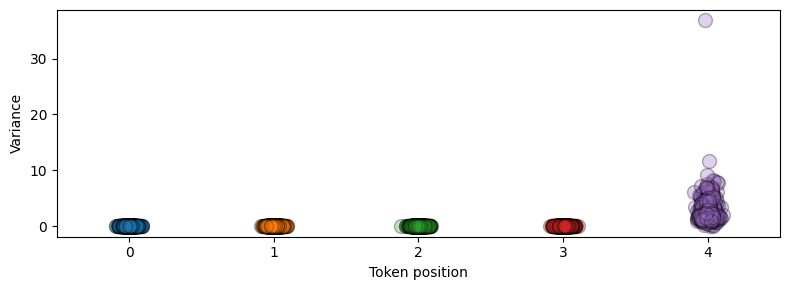

In [50]:
plt.figure(figsize=(8,3))

for i in range(batch.shape[1]):
  hs = outs.hidden_states[3][:,i,:]
  plt.plot(np.random.normal(i,.03,hs.shape[1]),hs.var(dim=0),'o',
           markeredgecolor='k',markersize=10,alpha=.3)

plt.gca().set(xlabel='Token position',ylabel='Variance',
              xticks=range(5),xlim=[-.5,4.5])

plt.tight_layout()
plt.show()

# Part_2:Cosine Similarities in one layer

## Task_1:
- Extract the category labels in the words variable into a NumPy array.
Make sure the array is a 34 × 1 column vector (not a dimensionless
array). Create a “category matrix mask” as the upper-triangle of an
outer product of the labels vector with itself (the outer product is a
linear algebra operation that creates a matrix from a vector as vv⊤).
Visualize that matrix as in Figure 5.11.

(34, 1)


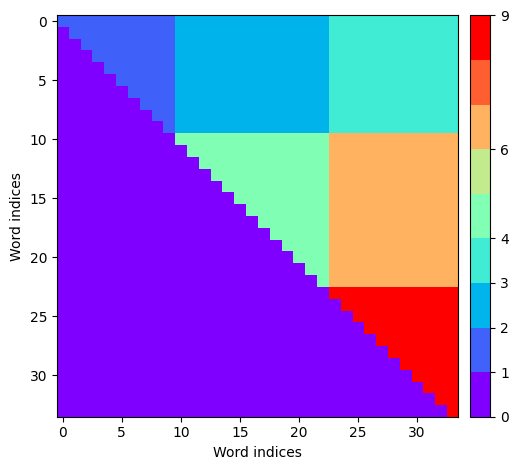

In [63]:
# vector of word categories
labels = np.array([[w[0] for w in words]]).T
print(labels.shape)

# mask for cosine similarity matrix
cat_mask = np.triu( labels @ labels.T)

# create a discrete colormap
N = cat_mask.max()
base = plt.get_cmap('rainbow')
cmapN = base.from_list(None,base(np.linspace(0,1,N)),N)

plt.imshow(cat_mask,cmap=cmapN)
plt.gca().set(xlabel='Word indices',ylabel='Word indices')
plt.colorbar(ticks=np.unique(cat_mask),pad=.02)

plt.tight_layout()
plt.show()

In [55]:
np.triu( labels @ labels.T)

array([[1, 1, 1, ..., 3, 3, 3],
       [0, 1, 1, ..., 3, 3, 3],
       [0, 0, 1, ..., 3, 3, 3],
       ...,
       [0, 0, 0, ..., 9, 9, 9],
       [0, 0, 0, ..., 0, 9, 9],
       [0, 0, 0, ..., 0, 0, 9]], shape=(34, 34))

In [56]:
np.triu( labels @ labels.T,1)

array([[0, 1, 1, ..., 3, 3, 3],
       [0, 0, 1, ..., 3, 3, 3],
       [0, 0, 0, ..., 3, 3, 3],
       ...,
       [0, 0, 0, ..., 0, 9, 9],
       [0, 0, 0, ..., 0, 0, 9],
       [0, 0, 0, ..., 0, 0, 0]], shape=(34, 34))

## Task_2:
- Choose one hidden-state layer (I used layer index 4). Extract
the hidden states for the final token, normalize the vectors, and
calculate the cosine similarity matrix as HH⊤ as you learned in
Chapter 3. Visualize that matrix as in Figure 5.12A and look for
a block-diagonal structure that would indicate differences between
within- vs. across-category similarities.
Extract all the within-category similarities into one vector, and
all the across-category similarities into another vector. Then show
histograms of those two groups as in Figure 5.12B, perform a
two-samples t-test to compare the distributions, and calculate a ∆
term as the difference between the means of the within- (w) and
across-category (a) similarities (∆ = w − a).

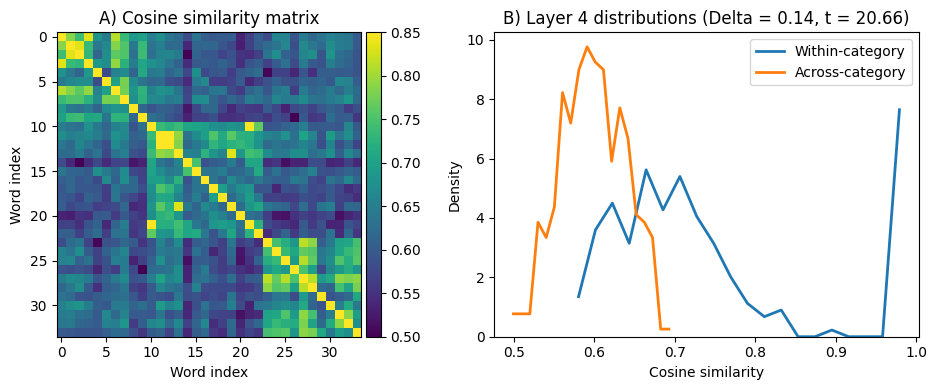

In [75]:
layeri = 4
hs = outs.hidden_states[layeri][:,-1,:]
hs /= torch.linalg.norm(hs,axis=1,keepdims=True)
csMat =  hs@hs.T

# extract the unique values
within = torch.concatenate((csMat[cat_mask==1],csMat[cat_mask==4],csMat[cat_mask==9]))
across = torch.concatenate((csMat[cat_mask==2],csMat[cat_mask==3],csMat[cat_mask==6]))

# t-test
tval = ttest_ind(within,across).statistic

# histograms
yWithin,xWithin = torch.histogram(within,bins=20,density=True)
yAcross,xAcross = torch.histogram(across,bins=20,density=True)

_,axs = plt.subplots(1,2,figsize=(10,4))
h = axs[0].imshow(csMat,vmin=.5,vmax=.85)
plt.colorbar(h,ax=axs[0],pad=.01)
axs[0].set(xlabel='Word index',ylabel='Word index',title='A) Cosine similarity matrix')

axs[1].plot(xWithin[:-1],yWithin,linewidth=2,label='Within-category')
axs[1].plot(xAcross[:-1],yAcross,linewidth=2,label='Across-category')
axs[1].set(ylim=[0,None],xlabel='Cosine similarity',ylabel='Density',
           title=f'B) Layer {layeri} distributions (Delta = {within.mean()-across.mean():.2f}, t = {tval:.2f})')
axs[1].legend()


plt.tight_layout()
plt.show()

# Part 3: Laminar profiles

## Task_1
- In a for-loop over the hidden layers, repeat the analysis you developed
in Part 2, and store the ∆ and t-values for each layer in a NumPy
array. Visualize the results as in Figure 5.13

In [80]:
num_hidden = len(outs.hidden_states)
# names of the layers, for the x-axis tick labels
layer_labels = ['Emb'] + [f'L{i}' for i in range(num_hidden-1)]

In [82]:
num_hidden

13

In [81]:
layer_labels

['Emb',
 'L0',
 'L1',
 'L2',
 'L3',
 'L4',
 'L5',
 'L6',
 'L7',
 'L8',
 'L9',
 'L10',
 'L11']

In [87]:
# initializations
dist_metrics = np.zeros((4,num_hidden))


for layeri in range(num_hidden):

  # cosine similarity matrix
  hs = outs.hidden_states[layeri][:,-1,:].squeeze()
  hs /= np.linalg.norm(hs,axis=1,keepdims=True)
  csMat = hs @hs.T

  # extract the similarity values
  w = torch.concatenate((csMat[cat_mask==1],csMat[cat_mask==4],csMat[cat_mask==9]))
  a = torch.concatenate((csMat[cat_mask==2],csMat[cat_mask==3],csMat[cat_mask==6]))

  # calculate the metrics
  dist_metrics[0,layeri] =w.mean()
  dist_metrics[1,layeri] =a.mean()
  dist_metrics[2,layeri] =w.mean()-a.mean()
  dist_metrics[3,layeri] =ttest_ind(w,a).statistic

/tmp/ipykernel_747/476465112.py:9: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  hs /= np.linalg.norm(hs,axis=1,keepdims=True)


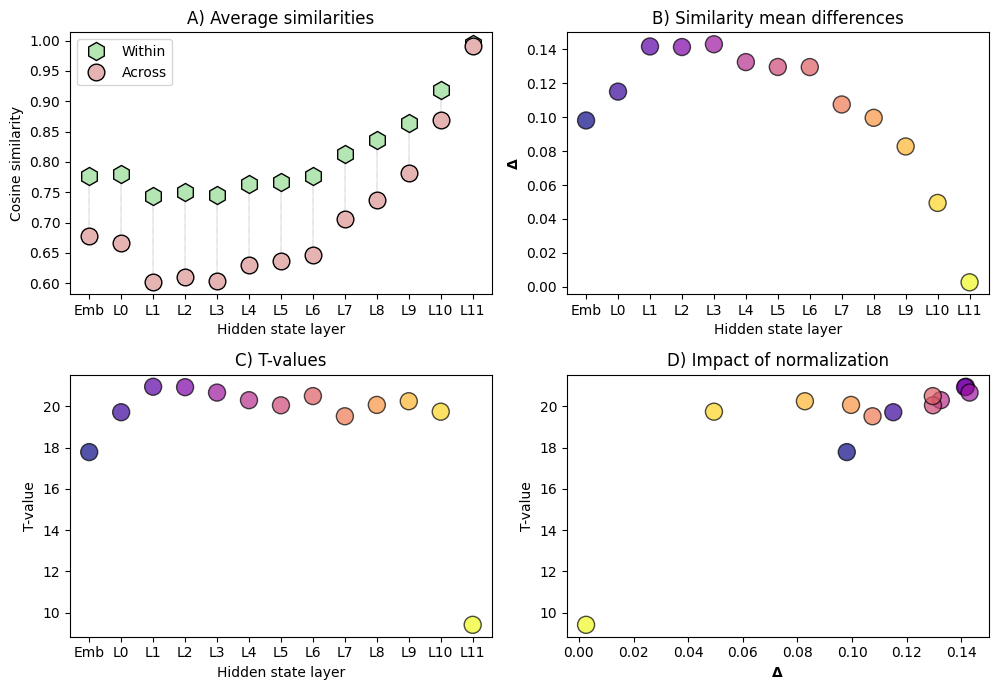

In [90]:
# show the results
_,axs = plt.subplots(2,2,figsize=(10,7))
axs[0,0].plot(dist_metrics[0,:],'kh',markerfacecolor=[.7,.9,.7],markersize=13,label='Within')
axs[0,0].plot(dist_metrics[1,:],'ko',markerfacecolor=[.9,.7,.7],markersize=12,label='Across')

# thin connecting lines representing \Delta
for i in range(1,num_hidden): # plot 0 separately for the legend
  axs[0,0].plot([i,i],dist_metrics[:2,i],'k:',linewidth=.3,zorder=-10)
axs[0,0].plot([0,0],dist_metrics[:2,0],'k:',linewidth=.3,zorder=-10,label='')

axs[0,0].legend()
axs[0,0].set(xlabel='Hidden state layer',xticks=range(len(layer_labels)),xticklabels=layer_labels,
           ylabel='Cosine similarity',title='A) Average similarities')


axs[0,1].scatter(range(num_hidden),dist_metrics[2,:],s=150,edgecolor='k',
            c=plt.cm.plasma(np.linspace(0,1,num_hidden)),alpha=.7)
axs[0,1].set(xlabel='Hidden state layer',xticks=range(len(layer_labels)),xticklabels=layer_labels,
           ylabel='$\\bf\\Delta$',title='B) Similarity mean differences')

axs[1,0].scatter(range(num_hidden),dist_metrics[3,:],s=150,edgecolor='k',
            c=plt.cm.plasma(np.linspace(0,1,num_hidden)),alpha=.7)
axs[1,0].set(xlabel='Hidden state layer',xticks=range(len(layer_labels)),xticklabels=layer_labels,
           ylabel='T-value',title='C) T-values')

axs[1,1].scatter(dist_metrics[2,:],dist_metrics[3,:],s=150,edgecolor='k',
            c=plt.cm.plasma(np.linspace(0,1,num_hidden)),alpha=.7)
axs[1,1].set(xlabel='$\\bf\\Delta$',ylabel='T-value',title='D) Impact of normalization')


plt.tight_layout()
plt.show()
